# Telco Customer Churn: EDA and Revenue Impact

**Dataset:** IBM Telco sample, 7,043 customers and 21 columns. Each row is one customer of a fictional telecom company that sells phone and internet service. The `Churn` column says whether the customer left.

**Questions this notebook answers**
1. Who churns, and what do those customers have in common?
2. How much revenue does churn cost, and which segments cost the most?
3. What should the business do about it?

**How to read this notebook**
- *Churn rate* is the share of a group that churned. We compare rates, not raw counts, because groups differ in size.
- Many patterns overlap (for example, month-to-month customers are also more often on fiber). When a pattern looks strong, we re-check it *within* another group to see whether it holds up.
- Everything here is an **association**. The data has no reasons for leaving, so we describe patterns and do not claim causes.

**Sections**
1. Setup and first look
2. Data cleaning
3. Churn analysis: contract, tenure, internet, payment, add-ons, demographics, phone and billing, charges
4. Revenue impact
5. Conclusion

## 1. Setup and first look

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'D:\PERSONAL PROJECTS\customer_churn_analysis\data\WA_Fn-UseC_-Telco-Customer-Churn.csv',encoding = 'unicode_escape')

### First look: structure and size
The first rows, last rows, shape, and whether every `customerID` is unique.

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [8]:
df.shape

(7043, 21)

In [6]:
df['customerID'].nunique()

7043

*so there are no duplicate columns here*

## 2. Data cleaning
Checks for nulls, blanks, duplicates and data types.

`isnull()` only catches truly empty cells. A blank string such as `" "` looks like normal text to pandas, so the next two cells check for those separately.

In [14]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [3]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


*so there are 11 rows where totalcharges are leave as space/blank*

In [35]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Fixing the data types
Two columns need fixing:
1. **`TotalCharges`** is stored as text because 11 rows contain a blank space. All 11 customers have `tenure = 0`, meaning they just signed up and have not been billed yet, so their total really is $0. We convert the column to numbers and fill those blanks with 0 (dropping them would throw away valid customers).
2. **`SeniorCitizen`** is 0/1 while every other flag is Yes/No. We map it to Yes/No so charts and tables are consistent.

**Run the `SeniorCitizen` cell only once.** Running it a second time finds no 0s or 1s to map and turns the whole column into NaN. If that happens, reload the CSV and rerun the cleaning cells in order.

In [4]:
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   str    
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## To make the analysis a little easier

### Helper columns
- **`churn_flag`**: `Churn` as 1/0. The average of this column inside any group *is* that group's churn rate.
- **`tenure_band`**: tenure grouped into 0-12, 13-24, 25-48 and 49-72 months, which gives much clearer charts than 73 separate values.

In [6]:
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)

In [7]:
df["tenure_band"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"],
)

In [8]:
df[["Churn", "churn_flag", "tenure", "tenure_band"]].head(10)
df["tenure_band"].value_counts().sort_index()

tenure_band
0-12 mo     2186
13-24 mo    1024
25-48 mo    1594
49-72 mo    2239
Name: count, dtype: int64

In [9]:
df.dtypes

customerID               str
gender                   str
SeniorCitizen            str
Partner                  str
Dependents               str
tenure                 int64
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges         float64
Churn                    str
churn_flag             int64
tenure_band         category
dtype: object

In [10]:
df.describe()

,tenure,MonthlyCharges,TotalCharges,churn_flag
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,0.265370
std,24.559481,30.090047,2266.794470,0.441561
min,0.000000,18.250000,0.000000,0.000000
25%,9.000000,35.500000,398.550000,0.000000
50%,29.000000,70.350000,1394.550000,0.000000
75%,55.000000,89.850000,3786.600000,1.000000
max,72.000000,118.750000,8684.800000,1.000000


### Cleaning summary
- No nulls and no duplicate rows or customer IDs.
- `TotalCharges` converted to numeric (11 blanks set to 0, all new customers with tenure 0).
- `SeniorCitizen` converted to Yes/No.
- Added `churn_flag` and `tenure_band`.
- **Decision:** the values "No internet service" and "No phone service" were **kept as separate categories**. Merging them into "No" would mix customers who *cannot* have an add-on with customers who *declined* it, and that hides how bad churn is among those who declined (for tech support, about 31% when merged versus 41.6% among internet customers who declined it).

## Exploratory Data Analysis

### How to read the tables below
Most tables come from a helper, `churn_by(column)`, defined a few cells further down. Its columns:
- `size`: customers in the group, `sum`: how many of them churned
- `churn_rate_%`: share of the group that churned
- `gap_vs_overall`: points above or below the overall churn rate
- `share_of_customers_%` and `share_of_churners_%`: comparing these two shows whether a group produces more churn than its size suggests

### 3.1 Churn baseline
How many customers churned versus stayed. Every other group is compared against this number.

In [10]:
churn_counts = df["Churn"].value_counts()
churn_pct = (df["Churn"].value_counts(normalize=True) * 100).round(1)

pd.DataFrame({"customers": churn_counts, "pct": churn_pct})

,customers,pct
Churn,,
No,5174,73.5
Yes,1869,26.5


*So the churn rate is 26.5 percent of the data*

### 3.2 Contract
First question: does the type of contract relate to churn? Start with churn rate and size per contract.

In [11]:
contract = df.groupby("Contract")["churn_flag"].agg(["size", "mean"])
contract["churn_rate_%"] = (contract["mean"] * 100).round(1)

contract[["size", "churn_rate_%"]]

,size,churn_rate_%
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


Adding context: how far each contract is from the overall rate, and how much of all churn it holds.

In [12]:
overall = df["churn_flag"].mean() * 100

contract = df.groupby("Contract")["churn_flag"].agg(["size", "sum", "mean"])
contract["churn_rate_%"] = (contract["mean"] * 100).round(1)
contract["gap_vs_overall"] = (contract["churn_rate_%"] - overall).round(1)
contract["share_of_churners_%"] = (contract["sum"] / contract["sum"].sum() * 100).round(1)

contract[["size", "sum", "churn_rate_%", "gap_vs_overall", "share_of_churners_%"]]

,size,sum,churn_rate_%,gap_vs_overall,share_of_churners_%
Contract,,,,,
Month-to-month,3875,1655,42.7,16.2,88.6
One year,1473,166,11.3,-15.2,8.9
Two year,1695,48,2.8,-23.7,2.6


A helper function so the same table can be produced for any column from here on.

In [13]:
overall = df["churn_flag"].mean() * 100

def churn_by(col):
    t = df.groupby(col, observed=True)["churn_flag"].agg(["size", "sum", "mean"])
    t["churn_rate_%"] = (t["mean"] * 100).round(1)
    t["gap_vs_overall"] = (t["churn_rate_%"] - overall).round(1)
    t["share_of_churners_%"] = (t["sum"] / t["sum"].sum() * 100).round(1)
    t["share_of_customers_%"] = (t["size"] / t["size"].sum() * 100).round(1)
    return t[["size", "sum", "churn_rate_%", "gap_vs_overall", "share_of_customers_%", "share_of_churners_%"]]

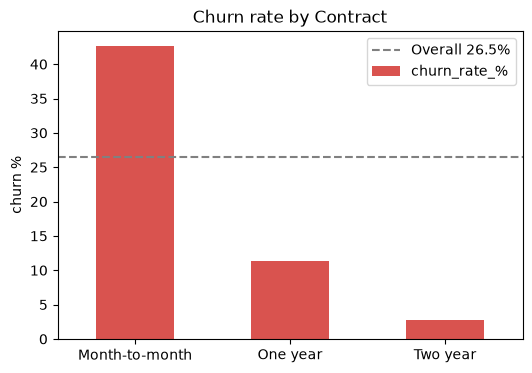

In [14]:
t = churn_by("Contract")
ax = t["churn_rate_%"].plot(kind="bar", color="#d9534f", figsize=(6, 4))
ax.axhline(overall, color="grey", ls="--", label=f"Overall {overall:.1f}%")
ax.set_title("Churn rate by Contract")
ax.set_ylabel("churn %")
ax.set_xlabel("")
ax.legend()
plt.xticks(rotation=0)
plt.show()

**Takeaway (contract):** month-to-month customers churn at **42.7%**, one-year at 11.3% and two-year at only 2.8%. Month-to-month customers are about 55% of the base but **88.6% of all churners**. Part of the two-year rate is lock-in (those customers cannot easily leave), so it should not be read as pure satisfaction.

### 3.3 Tenure
How long the customer has been with the company, in months.

In [15]:
churn_by("tenure_band")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
tenure_band,,,,,,
0-12 mo,2186,1037,47.4,20.9,31.0,55.5
13-24 mo,1024,294,28.7,2.2,14.5,15.7
25-48 mo,1594,325,20.4,-6.1,22.6,17.4
49-72 mo,2239,213,9.5,-17.0,31.8,11.4


#### Is it the contract, or just tenure?
New customers are more often on month-to-month, so the contract effect might be tenure in disguise. We check group sizes first (small groups give unstable rates), then churn by contract *within* each tenure band.

In [16]:
df.groupby(["tenure_band", "Contract"], observed=True).size().unstack()

Contract,Month-to-month,One year,Two year
tenure_band,,,
0-12 mo,1994,124,68
13-24 mo,737,197,90
25-48 mo,802,518,274
49-72 mo,342,634,1263


In [17]:
(df.pivot_table(index="tenure_band", columns="Contract", values="churn_flag", aggfunc="mean", observed=True) * 100).round(1)

Contract,Month-to-month,One year,Two year
tenure_band,,,
0-12 mo,51.4,10.5,0.0
13-24 mo,37.7,8.1,0.0
25-48 mo,32.9,10.6,2.2
49-72 mo,26.0,12.9,3.3


#### Who is on each contract?
Average tenure, bill, and share on fiber and electronic check for each contract type.

In [18]:
df.groupby("Contract").agg(
    avg_tenure=("tenure", "mean"),
    avg_monthly=("MonthlyCharges", "mean"),
    pct_fiber=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
    pct_echeck=("PaymentMethod", lambda s: (s == "Electronic check").mean() * 100),
).round(1)

,avg_tenure,avg_monthly,pct_fiber,pct_echeck
Contract,,,,
Month-to-month,18.0,66.4,54.9,47.7
One year,42.0,65.0,36.6,23.6
Two year,56.7,60.8,25.3,9.9


#### Dependents within contract
This check is used again in the demographics section: it shows that the dependents effect survives when contract is held fixed.

In [19]:
(df.pivot_table(index="Dependents", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
Dependents,,,
No,45.2,12.4,3.3
Yes,32.8,9.2,2.3


#### Tenure on its own (all customers)

In [20]:
churn_by("tenure_band")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
tenure_band,,,,,,
0-12 mo,2186,1037,47.4,20.9,31.0,55.5
13-24 mo,1024,294,28.7,2.2,14.5,15.7
25-48 mo,1594,325,20.4,-6.1,22.6,17.4
49-72 mo,2239,213,9.5,-17.0,31.8,11.4


#### When in the first year do customers leave?
The 0-12 month band is wide, so we split it into quarters. This is a snapshot of current customers, not a tracking of signups over time.

In [21]:
df["early_band"] = pd.cut(df[df["tenure"] <= 12]["tenure"], bins=[-1, 3, 6, 9, 12],
                          labels=["0-3", "4-6", "7-9", "10-12"])

(df.groupby("early_band", observed=True)["churn_flag"].agg(["size", "mean"])
   .assign(churn_rate=lambda t: (t["mean"] * 100).round(1))[["size", "churn_rate"]])

,size,churn_rate
early_band,,
0-3,1062,56.2
4-6,419,44.6
7-9,373,37.3
10-12,332,34.3


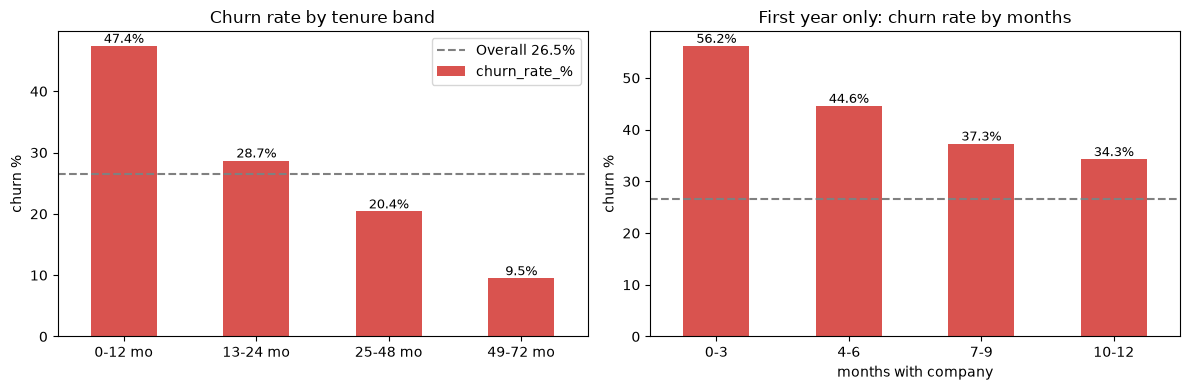

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: the four tenure bands
t = churn_by("tenure_band")
t["churn_rate_%"].plot(kind="bar", ax=axes[0], color="#d9534f")
axes[0].axhline(overall, color="grey", ls="--", label=f"Overall {overall:.1f}%")
axes[0].set_title("Churn rate by tenure band")
axes[0].set_ylabel("churn %")
axes[0].set_xlabel("")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=0)

# Right: the first year split finer
early = (df.groupby("early_band", observed=True)["churn_flag"].mean() * 100).round(1)
early.plot(kind="bar", ax=axes[1], color="#d9534f")
axes[1].axhline(overall, color="grey", ls="--")
axes[1].set_title("First year only: churn rate by months")
axes[1].set_ylabel("churn %")
axes[1].set_xlabel("months with company")
axes[1].tick_params(axis="x", rotation=0)

# Put the numbers on top of the bars
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

**Takeaway (tenure):** churn falls steadily with tenure, from **47.4%** in the first year to **9.5%** after four years. The first year holds 31% of customers but **55.5% of all churners**, and the first 3 months are the riskiest (**56.2%** churn). Contract still matters within every tenure band, so it is not just a tenure effect.

### 3.4 Internet service

In [23]:
churn_by("InternetService")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
InternetService,,,,,,
DSL,2421,459,19.0,-7.5,34.4,24.6
Fiber optic,3096,1297,41.9,15.4,44.0,69.4
No,1526,113,7.4,-19.1,21.7,6.0


#### Is fiber just a contract effect?
Churn by internet type within each contract.

In [24]:
(df.pivot_table(index="InternetService", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,32.2,9.3,1.9
Fiber optic,54.6,19.3,7.2
No,18.9,2.5,0.8


Average monthly bill by internet type.

In [25]:
df.groupby("InternetService")["MonthlyCharges"].mean().round(1)

InternetService
DSL            58.1
Fiber optic    91.5
No             21.1
Name: MonthlyCharges, dtype: float64

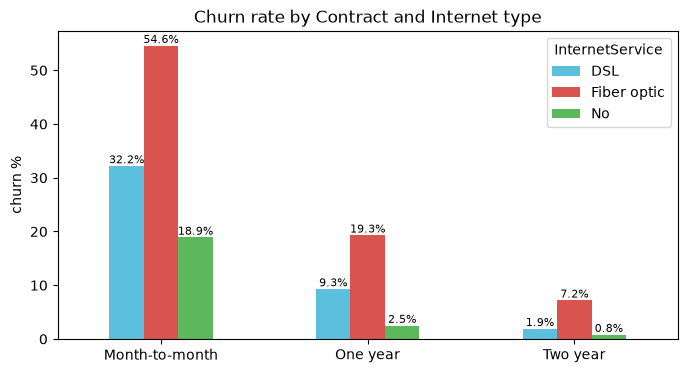

In [27]:
pivot = (df.pivot_table(index="Contract", columns="InternetService", values="churn_flag", aggfunc="mean") * 100).round(1)

ax = pivot.plot(kind="bar", figsize=(8, 4), color=["#5bc0de", "#d9534f", "#5cb85c"])
ax.set_title("Churn rate by Contract and Internet type")
ax.set_ylabel("churn %")
ax.set_xlabel("")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=8)
plt.show()

**Takeaway (internet):** fiber optic customers churn at **41.9%** (DSL 19.0%, no internet 7.4%). Fiber is 44% of customers but **69.4% of churners**. It stays the worst within every contract type, and it is also the most expensive product (about $91 a month versus $58 for DSL).

### 3.5 Payment method

In [28]:
churn_by("PaymentMethod")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
PaymentMethod,,,,,,
Bank transfer (automatic),1544,258,16.7,-9.8,21.9,13.8
Credit card (automatic),1522,232,15.2,-11.3,21.6,12.4
Electronic check,2365,1071,45.3,18.8,33.6,57.3
Mailed check,1612,308,19.1,-7.4,22.9,16.5


#### Within contract
Is electronic check bad only because of month-to-month customers?

In [28]:
(df.pivot_table(index="PaymentMethod", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.1,9.7,3.4
Credit card (automatic),32.8,10.3,2.2
Electronic check,53.7,18.4,7.7
Mailed check,31.6,6.8,0.8


#### Internet mix by payment method
This table has no churn in it. It describes who the customers are, and each row adds to 100%.

In [29]:
pd.crosstab(df["PaymentMethod"], df["InternetService"], normalize="index").mul(100).round(1)

InternetService,DSL,Fiber optic,No
PaymentMethod,,,
Bank transfer (automatic),36.7,41.8,21.5
Credit card (automatic),39.0,39.2,21.7
Electronic check,27.4,67.4,5.2
Mailed check,38.0,16.0,46.0


#### Within internet type
Is electronic check bad only because it is full of fiber customers?

In [30]:
(df.pivot_table(index="PaymentMethod", columns="InternetService", values="churn_flag", aggfunc="mean") * 100).round(1)

InternetService,DSL,Fiber optic,No
PaymentMethod,,,
Bank transfer (automatic),9.4,28.9,5.4
Credit card (automatic),12.1,25.3,2.7
Electronic check,31.9,53.2,12.3
Mailed check,20.7,42.6,9.6


**Takeaway (payment):** electronic check customers churn at **45.3%**, versus 15-19% for the other methods. They are a third of customers but **57.3% of churners**. The gap survives holding contract or internet type fixed. Automatic payment methods look stickier than mailed check once internet type is held fixed.

### 3.6 Add-on services
Only customers **with internet** are included here, because someone with no internet cannot buy an add-on and would distort the comparison.

#### Tech support, as the first example

In [31]:
internet = df[df["InternetService"] != "No"]

(internet.groupby("TechSupport")["churn_flag"].agg(["size", "mean"])
         .assign(churn_rate=lambda t: (t["mean"] * 100).round(1))[["size", "churn_rate"]])

,size,churn_rate
TechSupport,,
No,3473,41.6
Yes,2044,15.2


Tech support within each contract type.

In [32]:
(internet.pivot_table(index="TechSupport", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
TechSupport,,,
No,50.4,14.7,5.9
Yes,30.7,13.6,3.5


#### All six add-ons
Churn for customers without (No) and with (Yes) each add-on. `gap` is No minus Yes, in points.

In [33]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

addon_table = pd.DataFrame({
    a: (internet.groupby(a)["churn_flag"].mean() * 100).round(1) for a in addons
}).T

addon_table["gap"] = (addon_table["No"] - addon_table["Yes"]).round(1)
addon_table.sort_values("gap", ascending=False)

,No,Yes,gap
OnlineSecurity,41.8,14.6,27.2
TechSupport,41.6,15.2,26.4
OnlineBackup,39.9,21.5,18.4
DeviceProtection,39.1,22.5,16.6
StreamingMovies,33.7,29.9,3.8
StreamingTV,33.5,30.1,3.4


Same table, restricted to month-to-month customers, so contract cannot explain the gap.

In [34]:
mtm = internet[internet["Contract"] == "Month-to-month"]

pd.DataFrame({
    a: (mtm.groupby(a)["churn_flag"].mean() * 100).round(1) for a in addons
}).T.assign(gap=lambda t: (t["No"] - t["Yes"]).round(1))

,No,Yes,gap
OnlineSecurity,51.0,29.6,21.4
OnlineBackup,50.3,38.1,12.2
DeviceProtection,47.6,43.6,4.0
TechSupport,50.4,30.7,19.7
StreamingTV,43.8,50.6,-6.8
StreamingMovies,44.0,50.3,-6.3


**Takeaway (add-ons):** online security and tech support go with the lowest churn. Among month-to-month customers, churn is about **20 points lower** with them (51.0% vs 29.6% for security, 50.4% vs 30.7% for tech support). Backup is moderate (12 points), device protection mostly disappears once contract is held fixed (4 points), and **streaming does not help retention**. On one- and two-year contracts the gaps are tiny because those customers rarely churn anyway.

### 3.7 Demographics
#### Senior citizens

In [35]:
churn_by("SeniorCitizen")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
SeniorCitizen,,,,,,
No,5901,1393,23.6,-2.9,83.8,74.5
Yes,1142,476,41.7,15.2,16.2,25.5


Within contract.

In [36]:
(df.pivot_table(index="SeniorCitizen", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
SeniorCitizen,,,
No,39.6,10.7,2.7
Yes,54.6,15.3,4.1


Internet mix of seniors versus non-seniors (describes customers, rows add to 100%).

In [37]:
pd.crosstab(df["SeniorCitizen"], df["InternetService"], normalize="index").mul(100).round(1)

InternetService,DSL,Fiber optic,No
SeniorCitizen,,,
No,36.6,38.4,25.0
Yes,22.7,72.8,4.6


Within internet type.

In [38]:
(df.pivot_table(index="SeniorCitizen", columns="InternetService", values="churn_flag", aggfunc="mean") * 100).round(1)

InternetService,DSL,Fiber optic,No
SeniorCitizen,,,
No,17.6,39.9,7.3
Yes,30.1,47.3,9.6


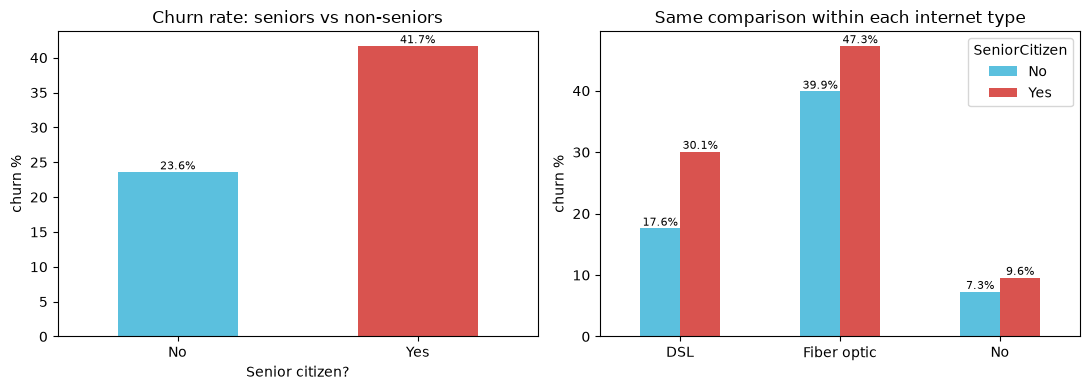

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: overall
overall_sr = (df.groupby("SeniorCitizen")["churn_flag"].mean() * 100).round(1)
overall_sr.plot(kind="bar", ax=axes[0], color=["#5bc0de", "#d9534f"])
axes[0].set_title("Churn rate: seniors vs non-seniors")
axes[0].set_ylabel("churn %")
axes[0].set_xlabel("Senior citizen?")

# Right: within each internet type
by_net = (df.pivot_table(index="InternetService", columns="SeniorCitizen",
                         values="churn_flag", aggfunc="mean") * 100).round(1)
by_net.plot(kind="bar", ax=axes[1], color=["#5bc0de", "#d9534f"])
axes[1].set_title("Same comparison within each internet type")
axes[1].set_ylabel("churn %")
axes[1].set_xlabel("")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", fontsize=8)

plt.tight_layout()
plt.show()

**Takeaway (seniors):** seniors churn at **41.7%** versus 23.6%. About 73% of seniors are on fiber (38% of non-seniors), which explains part of the gap, but seniors still churn about 7-12 points more within the same internet type.

#### Partner and dependents

In [40]:
churn_by("Partner")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
Partner,,,,,,
No,3641,1200,33.0,6.5,51.7,64.2
Yes,3402,669,19.7,-6.8,48.3,35.8


In [41]:
(df.pivot_table(index="Partner", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
Partner,,,
No,44.7,10.6,3.4
Yes,39.1,11.8,2.6


Dependents on their own.

In [42]:
churn_by("Dependents")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
Dependents,,,,,,
No,4933,1543,31.3,4.8,70.0,82.6
Yes,2110,326,15.5,-11.0,30.0,17.4


Dependents within contract.

In [43]:
(df.pivot_table(index="Dependents", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
Dependents,,,
No,45.2,12.4,3.3
Yes,32.8,9.2,2.3


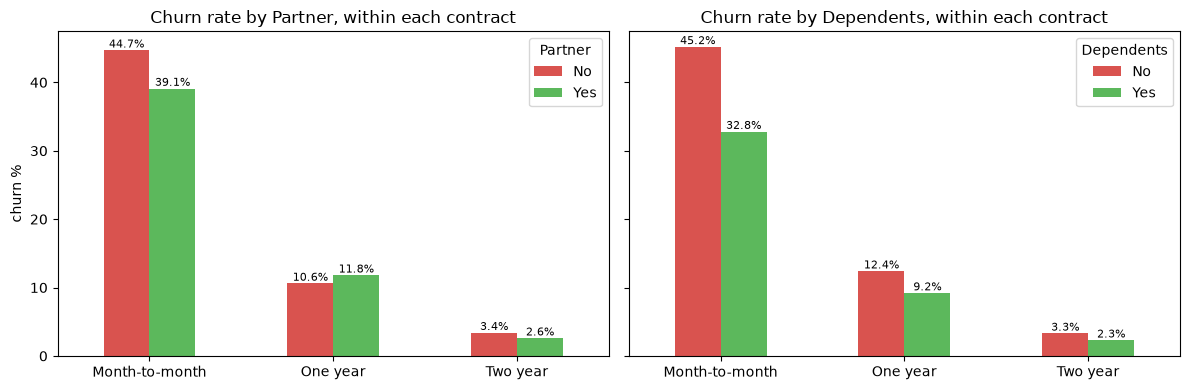

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, col in zip(axes, ["Partner", "Dependents"]):
    data = (df.pivot_table(index="Contract", columns=col, values="churn_flag", aggfunc="mean") * 100).round(1)
    data.plot(kind="bar", ax=ax, color=["#d9534f", "#5cb85c"])
    ax.set_title(f"Churn rate by {col}, within each contract")
    ax.set_xlabel("")
    ax.set_ylabel("churn %")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title=col)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", fontsize=8)

plt.tight_layout()
plt.show()

**Takeaway (partner and dependents):** customers with dependents churn about 16 points less (15.5% vs 31.3%), and the gap holds at about 12 points within month-to-month. The partner effect is mostly contract in disguise: within month-to-month it shrinks from 13 to about 6 points, and on longer contracts it is gone.

#### Gender

In [45]:
churn_by("gender")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
gender,,,,,,
Female,3488,939,26.9,0.4,49.5,50.2
Male,3555,930,26.2,-0.3,50.5,49.8


In [46]:
(df.pivot_table(index="gender", columns="Contract", values="churn_flag", aggfunc="mean") * 100).round(1)

Contract,Month-to-month,One year,Two year
gender,,,
Female,43.7,10.4,2.6
Male,41.7,12.1,3.1


In [47]:
(df.pivot_table(index="gender", columns="InternetService", values="churn_flag", aggfunc="mean") * 100).round(1)

InternetService,DSL,Fiber optic,No
gender,,,
Female,18.4,42.8,7.5
Male,19.5,41.0,7.3


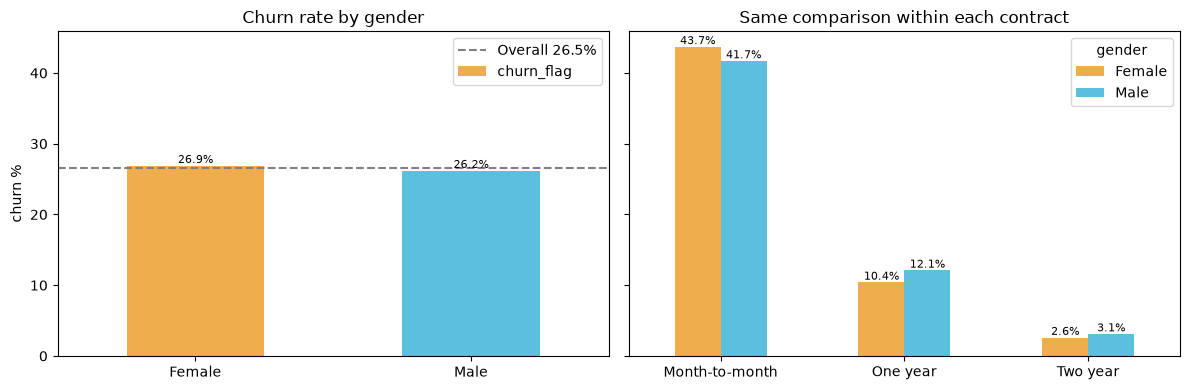

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# Left: overall
g = (df.groupby("gender")["churn_flag"].mean() * 100).round(1)
g.plot(kind="bar", ax=axes[0], color=["#f0ad4e", "#5bc0de"])
axes[0].axhline(overall, color="grey", ls="--", label=f"Overall {overall:.1f}%")
axes[0].set_title("Churn rate by gender")
axes[0].set_ylabel("churn %")
axes[0].set_xlabel("")
axes[0].legend()

# Right: within each contract
gc = (df.pivot_table(index="Contract", columns="gender", values="churn_flag", aggfunc="mean") * 100).round(1)
gc.plot(kind="bar", ax=axes[1], color=["#f0ad4e", "#5bc0de"])
axes[1].set_title("Same comparison within each contract")
axes[1].set_xlabel("")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", fontsize=8)

plt.tight_layout()
plt.show()

**Takeaway (gender):** no relationship. Women churn at 26.9% and men at 26.2%, and the difference stays within about 2 points across contract, internet type, partner and dependents. The direction flips from cell to cell, which is what random noise looks like.

### 3.8 Phone services
`MultipleLines` only applies to customers with phone service, so that comparison is limited to them.

In [49]:
display(churn_by("PhoneService"))

phone = df[df["PhoneService"] == "Yes"]
(phone.groupby("MultipleLines")["churn_flag"].agg(["size", "mean"])
      .assign(churn_rate=lambda t: (t["mean"] * 100).round(1))[["size", "churn_rate"]])

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
PhoneService,,,,,,
No,682,170,24.9,-1.6,9.7,9.1
Yes,6361,1699,26.7,0.2,90.3,90.9


,size,churn_rate
MultipleLines,,
No,3390,25.0
Yes,2971,28.6


Multiple lines within each internet type.

In [50]:
(phone.pivot_table(index="MultipleLines", columns="InternetService", values="churn_flag", aggfunc="mean") * 100).round(1)

InternetService,DSL,Fiber optic,No
MultipleLines,,,
No,20.6,45.8,8.7
Yes,10.6,39.6,2.9


Internet mix by number of lines (describes customers, rows add to 100%).

In [51]:
pd.crosstab(phone["MultipleLines"], phone["InternetService"], normalize="index").mul(100).round(1)

InternetService,DSL,Fiber optic,No
MultipleLines,,,
No,30.9,34.2,34.9
Yes,23.3,65.2,11.5


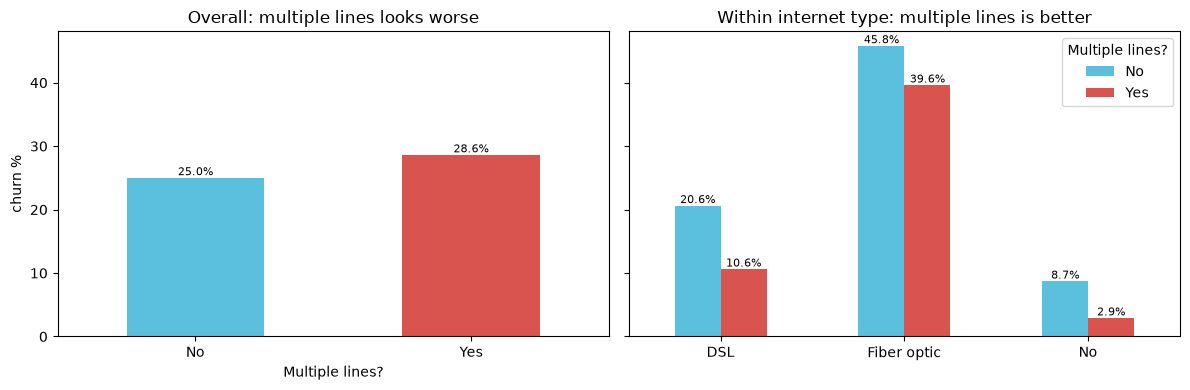

In [52]:
phone = df[df["PhoneService"] == "Yes"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# Left: overall (phone customers only)
ml = (phone.groupby("MultipleLines")["churn_flag"].mean() * 100).round(1)
ml.plot(kind="bar", ax=axes[0], color=["#5bc0de", "#d9534f"])
axes[0].set_title("Overall: multiple lines looks worse")
axes[0].set_ylabel("churn %")
axes[0].set_xlabel("Multiple lines?")

# Right: within each internet type
mi = (phone.pivot_table(index="InternetService", columns="MultipleLines",
                        values="churn_flag", aggfunc="mean") * 100).round(1)
mi.plot(kind="bar", ax=axes[1], color=["#5bc0de", "#d9534f"])
axes[1].set_title("Within internet type: multiple lines is better")
axes[1].set_xlabel("")
axes[1].legend(title="Multiple lines?")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", fontsize=8)

plt.tight_layout()
plt.show()

**Takeaway (phone):** phone service itself is flat (24.9% vs 26.7%). Multiple lines *looks* slightly worse overall (28.6% vs 25.0%), but that is a mix effect: 65% of multi-line customers are on fiber, while about 35% of single-line customers have no internet. Within each internet type, multi-line customers churn **6-10 points less**. This is an example of a pattern reversing once groups are compared fairly.

### 3.9 Paperless billing

In [53]:
churn_by("PaperlessBilling")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
PaperlessBilling,,,,,,
No,2872,469,16.3,-10.2,40.8,25.1
Yes,4171,1400,33.6,7.1,59.2,74.9


Payment method mix by paperless billing (describes customers, rows add to 100%).

In [54]:
pd.crosstab(df["PaperlessBilling"], df["PaymentMethod"], normalize="index").mul(100).round(1)

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
PaperlessBilling,,,,
No,22.7,22.3,21.7,33.3
Yes,21.4,21.1,41.8,15.7


Paperless versus not, within each payment method.

In [55]:
(df.pivot_table(index="PaymentMethod", columns="PaperlessBilling", values="churn_flag", aggfunc="mean") * 100).round(1)

PaperlessBilling,No,Yes
PaymentMethod,,
Bank transfer (automatic),11.0,20.9
Credit card (automatic),10.0,19.0
Electronic check,32.7,49.8
Mailed check,13.5,27.3


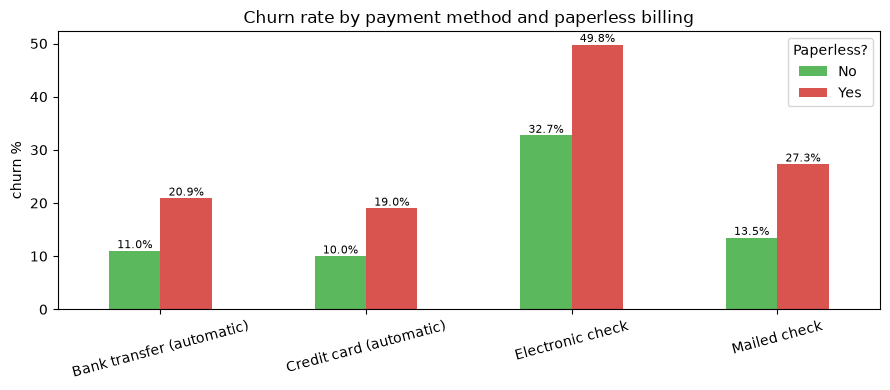

In [57]:
pb = (df.pivot_table(index="PaymentMethod", columns="PaperlessBilling",
                     values="churn_flag", aggfunc="mean") * 100).round(1)

ax = pb.plot(kind="bar", figsize=(9, 4), color=["#5cb85c", "#d9534f"])
ax.set_title("Churn rate by payment method and paperless billing")
ax.set_ylabel("churn %")
ax.set_xlabel("")
ax.legend(title="Paperless?")
plt.xticks(rotation=15)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=8)
plt.tight_layout()
plt.show()

**Takeaway (paperless):** paperless customers churn at **33.6%** versus 16.3%, and are 59% of customers but 75% of churners. Payment method explains part of that (paperless customers lean toward electronic check), but within every payment method paperless customers still churn **9-17 points more**. Electronic check plus paperless billing is the riskiest combination (49.8%).

### 3.10 Charges
#### Monthly and total charges, churners versus stayers

In [58]:
df.groupby("Churn")[["MonthlyCharges", "TotalCharges"]].agg(["mean", "median"]).round(1)

MonthlyCharges        TotalCharges        
                mean median         mean  median
Churn                                           
No              61.3   64.4       2549.9  1679.5
Yes             74.4   79.6       1531.8   703.6

#### Total charges within tenure band
Stayers look like they have paid more overall, but that is because they have been around longer. Comparing within a tenure band shows what is really going on.

In [59]:
df.pivot_table(index="tenure_band", columns="Churn", values="TotalCharges",
               aggfunc="median", observed=True).round(0)

Churn,No,Yes
tenure_band,,
0-12 mo,179.0,164.0
13-24 mo,980.0,1384.0
25-48 mo,2193.0,2896.0
49-72 mo,4894.0,5643.0


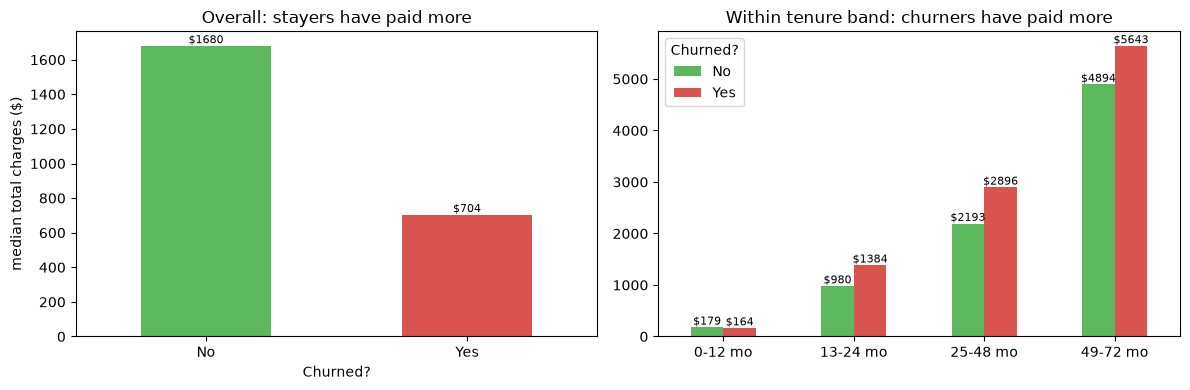

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: overall medians
overall_med = df.groupby("Churn")["TotalCharges"].median().round(0)
overall_med.plot(kind="bar", ax=axes[0], color=["#5cb85c", "#d9534f"])
axes[0].set_title("Overall: stayers have paid more")
axes[0].set_ylabel("median total charges ($)")
axes[0].set_xlabel("Churned?")
axes[0].tick_params(axis="x", rotation=0)

# Right: within each tenure band
by_band = df.pivot_table(index="tenure_band", columns="Churn", values="TotalCharges",
                         aggfunc="median", observed=True).round(0)
by_band.plot(kind="bar", ax=axes[1], color=["#5cb85c", "#d9534f"])
axes[1].set_title("Within tenure band: churners have paid more")
axes[1].set_xlabel("")
axes[1].legend(title="Churned?")
axes[1].tick_params(axis="x", rotation=0)

for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt="$%.0f", fontsize=8)

plt.tight_layout()
plt.show()

**Takeaway (total charges):** `TotalCharges` is roughly tenure times monthly charge, so it mostly repeats the tenure story. Within three of the four tenure bands, churners have actually been billed more, because they pay more per month. Churners pay about $74 a month versus $61 for stayers. We treat `MonthlyCharges` as the real money signal and drop `TotalCharges` as a driver.

#### Churn by monthly bill

In [61]:
df["monthly_band"] = pd.cut(df["MonthlyCharges"], bins=[0, 35, 70, 90, 120],
                            labels=["<$35", "$35-70", "$70-90", "$90+"])

churn_by("monthly_band")

,size,sum,churn_rate_%,gap_vs_overall,share_of_customers_%,share_of_churners_%
monthly_band,,,,,,
<$35,1735,189,10.9,-15.6,24.6,10.1
$35-70,1725,413,23.9,-2.6,24.5,22.1
$70-90,1844,697,37.8,11.3,26.2,37.3
$90+,1739,570,32.8,6.3,24.7,30.5


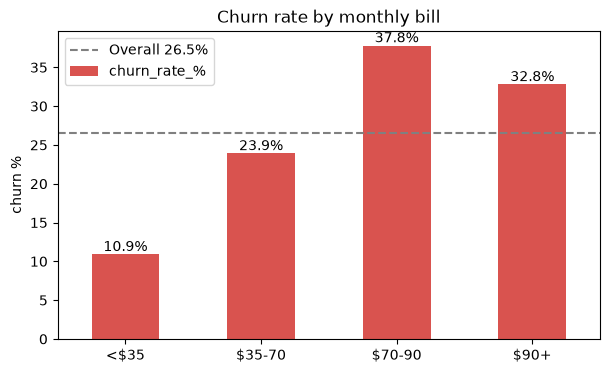

In [64]:
t = churn_by("monthly_band")
ax = t["churn_rate_%"].plot(kind="bar", color="#d9534f", figsize=(7, 4))
ax.axhline(overall, color="grey", ls="--", label=f"Overall {overall:.1f}%")
ax.set_title("Churn rate by monthly bill")
ax.set_ylabel("churn %")
ax.set_xlabel("")
ax.legend()
plt.xticks(rotation=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.show()

**Takeaway (monthly bill):** churn rises with price up to $70-90 (37.8%) and then dips at $90+ (32.8%). The cheapest band is safest (10.9%), mostly because it holds customers with no internet.

#### A puzzle: do higher bills really mean less churn inside fiber?
Among fiber customers only, churn by price band. The $35-70 band has just 112 customers, so its rate is unreliable and is ignored. The reliable comparison is $70-90 versus $90+.

In [62]:
fiber = df[df["InternetService"] == "Fiber optic"]
churn_by_fiber = fiber.groupby("monthly_band", observed=True)["churn_flag"].agg(["size", "mean"])
churn_by_fiber["churn_rate_%"] = (churn_by_fiber["mean"] * 100).round(1)
churn_by_fiber[["size", "churn_rate_%"]]

,size,churn_rate_%
monthly_band,,
$35-70,112,62.5
$70-90,1292,50.9
$90+,1692,33.6


Average number of add-ons by price band (describes customers, not churn): do pricier fiber bills mean more add-ons?

In [63]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

df["addon_count"] = (df[addons] == "Yes").sum(axis=1)
df["support_count"] = (df[["OnlineSecurity", "TechSupport"]] == "Yes").sum(axis=1)

fiber = df[df["InternetService"] == "Fiber optic"]

fiber.groupby("monthly_band", observed=True)[["addon_count", "support_count"]].mean().round(2)

,addon_count,support_count
monthly_band,,
$35-70,0.00,0.00
$70-90,1.20,0.27
$90+,3.76,0.80


#### Fiber churn by number of security + tech support add-ons
The row labels 0, 1 and 2 are how many of these two add-ons the customer has.

In [66]:
(fiber.groupby("support_count")["churn_flag"].agg(["size", "mean"])
      .assign(churn_rate=lambda t: (t["mean"] * 100).round(1))[["size", "churn_rate"]])

,size,churn_rate
support_count,,
0,1765,55.0
1,957,28.5
2,374,14.2


#### Fiber churn by number of the other four add-ons
Backup, device protection, streaming TV and streaming movies. Labels 0 to 4 are how many of the four the customer has.

In [71]:
other_addons = ["OnlineBackup", "DeviceProtection", "StreamingTV", "StreamingMovies"]

df["other_count"] = (df[other_addons] == "Yes").sum(axis=1)

fiber = df[df["InternetService"] == "Fiber optic"]   # re-create so it has the new column

(fiber.groupby("other_count")["churn_flag"].agg(["size", "mean"])
      .assign(churn_rate=lambda t: (t["mean"] * 100).round(1))[["size", "churn_rate"]])

,size,churn_rate
other_count,,
0,505,54.5
1,649,50.8
2,752,42.8
3,712,35.3
4,478,24.9


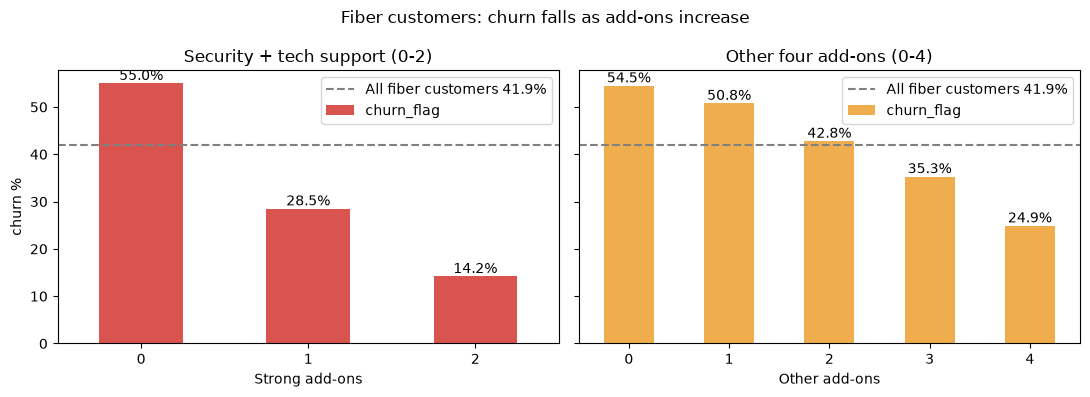

In [75]:
fiber_avg = fiber["churn_flag"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

a = (fiber.groupby("support_count")["churn_flag"].mean() * 100).round(1)
a.plot(kind="bar", ax=axes[0], color="#d9534f")
axes[0].set_title("Security + tech support (0-2)")
axes[0].set_xlabel("Strong add-ons")
axes[0].set_ylabel("churn %")

b = (fiber.groupby("other_count")["churn_flag"].mean() * 100).round(1)
b.plot(kind="bar", ax=axes[1], color="#f0ad4e")
axes[1].set_title("Other four add-ons (0-4)")
axes[1].set_xlabel("Other add-ons")

for ax in axes:
    ax.axhline(fiber_avg, color="grey", ls="--", label=f"All fiber customers {fiber_avg:.1f}%")
    ax.tick_params(axis="x", rotation=0)
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.legend()

fig.suptitle("Fiber customers: churn falls as add-ons increase", fontsize=12)
plt.tight_layout()
plt.show()

Churn by total add-ons, in bands. This counts how many add-ons a customer has but not which ones, so it is less clear than the two tables above and is kept as supporting evidence.

In [67]:
fiber = df[df["InternetService"] == "Fiber optic"]   # re-create so it has the new columns

fiber["addon_band"] = pd.cut(fiber["addon_count"], bins=[-1, 0, 2, 4, 6],
                             labels=["0", "1-2", "3-4", "5-6"])

(fiber.groupby("addon_band", observed=True)["churn_flag"].agg(["size", "mean"])
      .assign(churn_rate=lambda t: (t["mean"] * 100).round(1))[["size", "churn_rate"]])

,size,churn_rate
addon_band,,
0,399,60.4
1-2,1130,51.9
3-4,1136,35.3
5-6,431,16.0


**Takeaway (fiber puzzle):** among fiber customers, higher bills go with **less** churn ($70-90: 50.9%, $90+: 33.6%). The pricier fiber bills are mostly add-ons (about 3.8 add-ons versus 1.2), and add-ons go with lower churn. With neither security nor tech support, fiber churn is **55.0%**; with one it is 28.5%; with both, **14.2%**. The other four add-ons help too, but much less per add-on (54.5% with none, 24.9% with all four). This fits the story but is not proof that add-ons cause retention.

## 4. Revenue impact
So far we looked at *who* leaves. Here we look at *what it costs*. All revenue figures use `MonthlyCharges`, so they are **monthly snapshots** of what customers were paying, not forecasts of annual loss, and the dataset has no cost data, so these are revenue and not profit.

**Margin** in this section means a difference in shares, in percentage points:
- For churners versus stayers: share of revenue minus share of customers.
- For segments: share of lost revenue minus share of churners. A positive value means that segment's churners pay more than the typical churner.

In [77]:
rev = df.groupby("Churn")["MonthlyCharges"].agg(["size", "sum", "mean"]).round(1)

rev["share_of_customers_%"] = (rev["size"] / rev["size"].sum() * 100).round(1)
rev["share_of_revenue_%"] = (rev["sum"] / rev["sum"].sum() * 100).round(1)
rev["margin_pts"] = (rev["share_of_revenue_%"] - rev["share_of_customers_%"]).round(1)

rev

,size,sum,mean,share_of_customers_%,share_of_revenue_%,margin_pts
Churn,,,,,,
No,5174,316985.8,61.3,73.5,69.5,-4.0
Yes,1869,139130.8,74.4,26.5,30.5,4.0


A helper like `churn_by`, but for lost revenue (churners only).

In [ ]:
def revenue_by(col):
    ch = df[df["churn_flag"] == 1]
    t = pd.DataFrame({
        "churners": ch.groupby(col, observed=True).size(),
        "revenue_lost": ch.groupby(col, observed=True)["MonthlyCharges"].sum(),
    })
    t["avg_bill_churners"] = (t["revenue_lost"] / t["churners"]).round(1)
    t["share_of_churners_%"] = (t["churners"] / t["churners"].sum() * 100).round(1)
    t["share_of_lost_rev_%"] = (t["revenue_lost"] / t["revenue_lost"].sum() * 100).round(1)
    t["margin_pts"] = (t["share_of_lost_rev_%"] - t["share_of_churners_%"]).round(1)
    t["revenue_lost"] = t["revenue_lost"].round(0)
    return t

pd.set_option("display.width", 200)
revenue_by("Contract")

,churners,revenue_lost,avg_bill_churners,share_of_churners_%,share_of_lost_rev_%,margin_pts
Contract,,,,,,
Month-to-month,1655,120847.0,73.0,88.6,86.9,-1.7
One year,166,14118.0,85.1,8.9,10.1,1.2
Two year,48,4165.0,86.8,2.6,3.0,0.4


#### Revenue lost by internet type

In [80]:
revenue_by("InternetService")

,churners,revenue_lost,avg_bill_churners,share_of_churners_%,share_of_lost_rev_%,margin_pts
InternetService,,,,,,
DSL,459,22529.0,49.1,24.6,16.2,-8.4
Fiber optic,1297,114300.0,88.1,69.4,82.2,12.8
No,113,2302.0,20.4,6.0,1.7,-4.3


**Takeaway (revenue by internet type):** fiber is 69.4% of churners but **82.2% of lost revenue** (margin +12.8), because fiber churners pay about $88 a month versus $49 for DSL. Fiber costs more in dollars than in headcount.

#### Where the money comes from versus where it leaves
Contract and internet type combined (9 segments): each segment's share of all revenue next to its share of all lost revenue.

In [81]:
df["lost_revenue"] = df["MonthlyCharges"] * df["churn_flag"]

seg = df.groupby(["Contract", "InternetService"]).agg(
    customers=("churn_flag", "size"),
    monthly_revenue=("MonthlyCharges", "sum"),
    revenue_lost=("lost_revenue", "sum"),
    churn_rate=("churn_flag", "mean"),
)

seg["churn_rate_%"] = (seg["churn_rate"] * 100).round(1)
seg["share_of_all_rev_%"] = (seg["monthly_revenue"] / seg["monthly_revenue"].sum() * 100).round(1)
seg["share_of_all_lost_%"] = (seg["revenue_lost"] / seg["revenue_lost"].sum() * 100).round(1)
seg[["monthly_revenue", "revenue_lost"]] = seg[["monthly_revenue", "revenue_lost"]].round(0)

pd.set_option("display.width", 250)
seg.drop(columns="churn_rate").sort_values("revenue_lost", ascending=False)

customers  monthly_revenue  revenue_lost  churn_rate_%  share_of_all_rev_%  share_of_all_lost_%
Contract       InternetService                                                                                                 
Month-to-month Fiber optic           2128         185181.0      100482.0          54.6                40.6                 72.2
               DSL                   1223          61418.0       18367.0          32.2                13.5                 13.2
One year       Fiber optic            539          53242.0       10572.0          19.3                11.7                  7.6
               DSL                    570          34996.0        3356.0           9.3                 7.7                  2.4
Two year       Fiber optic            429          44861.0        3246.0           7.2                 9.8                  2.3
Month-to-month No                     524          10695.0        1998.0          18.9                 2.3                  1.4
Two year       DSL                    628          44251.0         806.0           1.9                 9.7                  0.6
One year       No                     364           7578.0         190.0           2.5                 1.7                  0.1
Two year       No                     638          13894.0         114.0           0.8                 3.0                  0.1

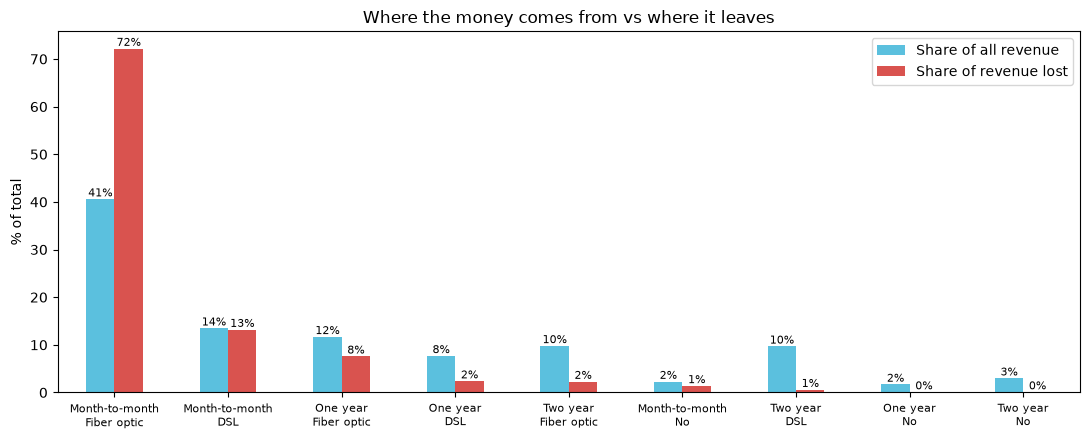

In [82]:
plot = seg[["share_of_all_rev_%", "share_of_all_lost_%"]].copy()
plot.index = [f"{c}\n{i}" for c, i in plot.index]
plot = plot.sort_values("share_of_all_lost_%", ascending=False)
plot.columns = ["Share of all revenue", "Share of revenue lost"]

ax = plot.plot(kind="bar", figsize=(11, 4.5), color=["#5bc0de", "#d9534f"])
ax.set_title("Where the money comes from vs where it leaves")
ax.set_ylabel("% of total")
ax.set_xlabel("")
plt.xticks(rotation=0, fontsize=8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8)
plt.tight_layout()
plt.show()

**Takeaway (segments):** **month-to-month fiber** is the biggest customer group and the biggest leak. It is 2,128 customers, **40.6% of all monthly revenue** and **72.2% of all lost revenue** (about $100K a month), with a 54.6% churn rate. The two-year contracts (fiber and DSL) bring in about 19.5% of revenue and account for under 3% of the loss, so they are the stable core.

---

## 5. Conclusion

### The overall picture
- **26.5%** of customers churned (1,869 of 7,043), about 1 in 4.
- Churn is concentrated in a recognisable profile: **new customers on month-to-month contracts, using fiber optic, paying by electronic check, without security or tech support.**
- Monthly revenue is about **$456K**. About **$139K (30.5%)** of it belongs to customers who churned. That is more than their 26.5% share of customers, because churners pay more per month ($74 vs $61).

### What matters, from strongest to weakest
| Strength | Columns | Evidence |
|---|---|---|
| **Strong** | Contract, tenure, internet type, payment method, online security, tech support | Month-to-month 42.7% vs two-year 2.8%. First year 47.4% vs 9.5% after four years. Fiber 41.9% vs DSL 19.0%. Electronic check 45.3% vs 15-19%. About 20 points lower with security or tech support on month-to-month. |
| **Moderate** | Paperless billing, dependents, senior citizen, online backup | Paperless 9-17 points higher within every payment method. Dependents about 12 points lower within month-to-month. Seniors 7-12 points higher within internet type. |
| **Weak or none** | Gender, phone service, partner, streaming, device protection | Gender 26.9% vs 26.2%. Partner mostly explained by contract. Streaming does not lower churn. |

### Where the money is
- **Month-to-month fiber** is both the biggest and the riskiest segment: 40.6% of revenue and 72.2% of lost revenue.
- Fiber costs more in dollars than in headcount (69.4% of churners, 82.2% of lost revenue).
- Two-year contracts are the stable core: about 19.5% of revenue with under 3% of the loss.

### Recommendations
These follow the patterns above. Because the data is observational, each one should be tested (for example with a pilot) before being rolled out widely.
1. **Focus retention on the first 90 days.** About a third of all churn comes from customers in their first 3 months. Onboarding calls and early check-ins are the cheapest place to start.
2. **Move month-to-month customers onto longer contracts**, starting with fiber customers. It is the biggest and most consistent signal in the data.
3. **Offer or bundle online security and tech support**, especially to fiber customers on month-to-month. Customers with them churn far less, though people who choose them may already be more committed.
4. **Review the fiber product and its price-to-value.** Fiber is the highest-churn product in every contract type, and it is where most revenue is lost.
5. **Look into the electronic check and paperless billing experience**, and consider nudging customers toward automatic payment. Electronic check with paperless billing is the riskiest combination (49.8%).
6. **Do not target by gender or phone service.** They show no signal.

### Limitations
- **Associations, not causes.** The data has no reasons for leaving, so patterns describe who churns, not why.
- **No dates.** Tenure is the closest thing to time, and the data is a snapshot, so we cannot say how a given signup cohort behaves over time.
- **Revenue is a snapshot.** Lost revenue is what churned customers were paying per month, not a forecast, and there is no cost data, so profit cannot be measured.
- **Overlapping variables.** Contract, tenure, internet type and add-ons are tangled together. We checked the main overlaps one pair at a time, but not every combination at once, and no statistical model was fitted.
- **Small groups** (for example two-year contracts in the first two years) give unstable rates and were not over-interpreted.

### Possible next steps
- Rank the highest-risk combinations (for example month-to-month + fiber + electronic check + no support).
- Fit a simple churn prediction model, using the cleaned columns and helper features built here.
- Build the dashboard from the findings above: KPI cards (customers, churn rate, revenue lost), segment charts, tenure curve and filters.